
# 1. Data Understanding

## 1.1 Connect Google Drive

Mount Google Drive to access the eight road crash CSV files directly in Google Colab.


In [ ]:

from google.colab import drive

# Connect Google Drive to Colab
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## 1.2 Load the Eight Datasets

Import the eight road crash CSV files from Google Drive into pandas DataFrames for data inspection and analysis.


In [ ]:
import pandas as pd

# Folder containing our CSV files
path = "/content/drive/MyDrive/Victoria RoadSafe - Crash Intelligence and Severity Prediction/Raw_Data/"

# Load datasets
accident = pd.read_csv(path + "accident.csv")
event = pd.read_csv(path + "accident_event.csv")
location = pd.read_csv(path + "accident_location.csv")
weather = pd.read_csv(path + "atmospheric_cond.csv")
node = pd.read_csv(path + "node.csv")
person = pd.read_csv(path + "person.csv")
surface = pd.read_csv(path + "road_surface_cond.csv")
vehicle = pd.read_csv(path + "vehicle.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!



## 1.3 Initial Dataset Inspection

Examine the number of rows and columns in each dataset to understand its size and structure before data cleaning and integration.


In [ ]:

# Store all eight DataFrames in a dictionary
datasets = {
    "Accident": accident,
    "Event": event,
    "Location": location,
    "Weather": weather,
    "Node": node,
    "Person": person,
    "Surface": surface,
    "Vehicle": vehicle
}

# Display the number of rows and columns in each dataset
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Accident: 202,297 rows, 23 columns
Event: 332,090 rows, 13 columns
Location: 202,297 rows, 9 columns
Weather: 204,866 rows, 4 columns
Node: 407,410 rows, 11 columns
Person: 472,364 rows, 14 columns
Surface: 203,374 rows, 4 columns
Vehicle: 369,181 rows, 37 columns



## 1.4 Examine Column Names and Data Types

Inspect the column names and data types of all eight datasets to understand what information is available and identify potential joining keys.


In [ ]:

# Display column names and data types for each dataset
for name, df in datasets.items():
    print(f"\n{name} Dataset")
    print(df.dtypes.to_string())



Accident Dataset
ACCIDENT_NO            object
ACCIDENT_DATE          object
ACCIDENT_TIME          object
ACCIDENT_TYPE           int64
ACCIDENT_TYPE_DESC     object
DAY_OF_WEEK             int64
DAY_WEEK_DESC          object
DCA_CODE                int64
DCA_DESC               object
LIGHT_CONDITION         int64
NODE_ID               float64
NO_OF_VEHICLES          int64
NO_PERSONS_KILLED       int64
NO_PERSONS_INJ_2        int64
NO_PERSONS_INJ_3        int64
NO_PERSONS_NOT_INJ      int64
NO_PERSONS              int64
POLICE_ATTEND           int64
ROAD_GEOMETRY           int64
ROAD_GEOMETRY_DESC     object
SEVERITY                int64
SPEED_ZONE              int64
RMA                    object

Event Dataset
ACCIDENT_NO               object
EVENT_SEQ_NO               int64
EVENT_TYPE                object
EVENT_TYPE_DESC           object
VEHICLE_1_ID              object
VEHICLE_1_COLL_PT         object
VEHICLE 1 COLL PT DESC    object
VEHICLE_2_ID              object
VEHICLE_2_COL


## 1.5 Check Unique Accident IDs and Duplicate Records

Check the number of unique accident IDs and duplicate records in each dataset to understand table relationships and prevent incorrect results when joining data.


In [ ]:

# Check accident IDs and duplicate records across datasets
for name, df in datasets.items():
    print(f"\n{name} Dataset")
    print("Total Rows:", len(df))
    print("Unique Accident IDs:", df["ACCIDENT_NO"].nunique())
    print("Duplicate Rows:", df.duplicated().sum())



Accident Dataset
Total Rows: 202297
Unique Accident IDs: 202297
Duplicate Rows: 0

Event Dataset
Total Rows: 332090
Unique Accident IDs: 200996
Duplicate Rows: 0

Location Dataset
Total Rows: 202297
Unique Accident IDs: 202297
Duplicate Rows: 0

Weather Dataset
Total Rows: 204866
Unique Accident IDs: 202297
Duplicate Rows: 0

Node Dataset
Total Rows: 407410
Unique Accident IDs: 201003
Duplicate Rows: 203250

Person Dataset
Total Rows: 472364
Unique Accident IDs: 202297
Duplicate Rows: 0

Surface Dataset
Total Rows: 203374
Unique Accident IDs: 202296
Duplicate Rows: 0

Vehicle Dataset
Total Rows: 369181
Unique Accident IDs: 202287
Duplicate Rows: 0



## 1.6 Check Missing Values

Identify missing values in each dataset to assess data completeness and determine which columns may require cleaning before analysis.


In [ ]:

# Calculate missing values for each column
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100

    # Display only columns containing missing values
    result = pd.DataFrame({
        "Missing Values": missing,
        "Missing (%)": missing_pct.round(2)
    })

    result = result[result["Missing Values"] > 0]

    print(f"\n{name} Dataset")
    print(result.to_string() if not result.empty else "No missing values")



Accident Dataset
         Missing Values  Missing (%)
NODE_ID            1209          0.6
RMA                8893          4.4

Event Dataset
                        Missing Values  Missing (%)
EVENT_TYPE                           1         0.00
EVENT_TYPE_DESC                      1         0.00
VEHICLE_1_ID                         1         0.00
VEHICLE_1_COLL_PT                    1         0.00
VEHICLE 1 COLL PT DESC            2741         0.83
VEHICLE_2_ID                    172655        51.99
VEHICLE_2_COLL_PT               172708        52.01
VEHICLE 2 COLL PT DESC          172992        52.09
PERSON_ID                       310636        93.54

Location Dataset
                    Missing Values  Missing (%)
NODE_ID                       1209         0.60
ROAD_ROUTE_1                  1294         0.64
ROAD_NAME                     1472         0.73
ROAD_TYPE                     3968         1.96
ROAD_NAME_INT                 2100         1.04
ROAD_TYPE_INT                 


## 1.7 Validate Accident IDs Across Datasets

Check whether the accident IDs in each related dataset exist in the main Accident table, and identify accidents without matching records.

This helps us assess data relationships and plan reliable joins.


In [ ]:

# Get all unique accident IDs from the main table
main_ids = set(accident["ACCIDENT_NO"])

# Compare accident IDs across the related datasets
for name, df in datasets.items():

    if name == "Accident":
        continue

    related_ids = set(df["ACCIDENT_NO"])

    # Accidents missing from the related dataset
    missing = main_ids - related_ids

    # IDs in the related dataset but not in the main table
    extra = related_ids - main_ids

    print(f"{name}: {len(missing)} missing matches, {len(extra)} extra IDs")


Event: 1301 missing matches, 0 extra IDs
Location: 0 missing matches, 0 extra IDs
Weather: 0 missing matches, 0 extra IDs
Node: 1294 missing matches, 0 extra IDs
Person: 0 missing matches, 0 extra IDs
Surface: 1 missing matches, 0 extra IDs
Vehicle: 10 missing matches, 0 extra IDs



## 1.8 Handle Duplicate Node Records

Remove exact duplicate records from the Node dataset and check whether multiple records still exist for the same accident.

**Purpose:** Prevent duplicate accident counts when creating the master dataset.


In [ ]:

# Remove exact duplicate rows
node = node.drop_duplicates().copy()

# Check remaining records
print("Total Rows:", len(node))
print("Unique Accidents:", node["ACCIDENT_NO"].nunique())

# Check accidents with multiple node records
multiple_nodes = node["ACCIDENT_NO"].value_counts()

print("Accidents with Multiple Nodes:",
      (multiple_nodes > 1).sum())


Total Rows: 204160
Unique Accidents: 201003
Accidents with Multiple Nodes: 3148



# 2. Data Preparation and Integration

## 2.1 Select Required Columns

Select the 36 agreed source-column selections from seven datasets.

**Objective:** Remove unnecessary variables, preserve the original datasets, and prepare focused working tables for cleaning and integration.


In [ ]:

# Accident data
accident_clean = accident[[
    "ACCIDENT_NO", "ACCIDENT_DATE", "ACCIDENT_TIME",
    "ACCIDENT_TYPE_DESC", "DCA_DESC", "LIGHT_CONDITION",
    "NO_OF_VEHICLES", "NO_PERSONS_KILLED",
    "NO_PERSONS_INJ_2", "NO_PERSONS_INJ_3",
    "ROAD_GEOMETRY_DESC", "SEVERITY", "SPEED_ZONE", "RMA"
]].copy()

# Location data
location_clean = location[[
    "ACCIDENT_NO", "ROAD_NAME", "ROAD_TYPE"
]].copy()

# Weather data
weather_clean = weather[[
    "ACCIDENT_NO", "ATMOSPH_COND_DESC"
]].copy()

# Geographic data
node_clean = node[[
    "ACCIDENT_NO", "LGA_NAME", "DEG_URBAN_NAME",
    "LATITUDE", "LONGITUDE"
]].copy()

# Person data
person_clean = person[[
    "ACCIDENT_NO", "AGE_GROUP", "SEX",
    "INJ_LEVEL_DESC", "ROAD_USER_TYPE_DESC"
]].copy()

# Vehicle data
vehicle_clean = vehicle[[
    "ACCIDENT_NO", "VEHICLE_YEAR_MANUF",
    "VEHICLE_TYPE_DESC", "TOTAL_NO_OCCUPANTS",
    "TRAFFIC_CONTROL_DESC"
]].copy()

# Road surface data
surface_clean = surface[[
    "ACCIDENT_NO", "SURFACE_COND_DESC"
]].copy()

# Check selected datasets
selected_datasets = {
    "Accident": accident_clean,
    "Location": location_clean,
    "Weather": weather_clean,
    "Node": node_clean,
    "Person": person_clean,
    "Vehicle": vehicle_clean,
    "Surface": surface_clean
}

for name, df in selected_datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")


Accident: 202,297 rows, 14 columns
Location: 202,297 rows, 3 columns
Weather: 204,866 rows, 2 columns
Node: 204,160 rows, 5 columns
Person: 472,364 rows, 5 columns
Vehicle: 369,181 rows, 5 columns
Surface: 203,374 rows, 2 columns



## 2.2 Clean Accident Dates and Times

Convert accident dates and times into usable formats and create features for time-based analysis.

**Purpose:** Analyse crash patterns by year, month, weekday and hour for Power BI and Machine Learning.


In [ ]:

# Convert accident dates into datetime format
accident_clean["ACCIDENT_DATE"] = pd.to_datetime(
    accident_clean["ACCIDENT_DATE"],
    dayfirst=True,
    errors="coerce"
)

# Extract accident hour from time
accident_clean["HOUR"] = pd.to_datetime(
    accident_clean["ACCIDENT_TIME"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

# Create time-based features
accident_clean["YEAR"] = accident_clean["ACCIDENT_DATE"].dt.year
accident_clean["MONTH"] = accident_clean["ACCIDENT_DATE"].dt.month
accident_clean["DAY_OF_WEEK"] = accident_clean["ACCIDENT_DATE"].dt.day_name()

# Check invalid dates and times
print("Invalid Dates:", accident_clean["ACCIDENT_DATE"].isna().sum())
print("Invalid Times:", accident_clean["HOUR"].isna().sum())

# Display results
display(accident_clean[[
    "ACCIDENT_DATE", "ACCIDENT_TIME",
    "YEAR", "MONTH", "DAY_OF_WEEK", "HOUR"
]].head())


Invalid Dates: 0
Invalid Times: 0


/tmp/ipykernel_6292/2280643478.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  accident_clean["ACCIDENT_DATE"] = pd.to_datetime(


,ACCIDENT_DATE,ACCIDENT_TIME,YEAR,MONTH,DAY_OF_WEEK,HOUR
0,2012-01-31,10:35:00,2012,1,Tuesday,10
1,2012-02-02,07:55:00,2012,2,Thursday,7
2,2012-02-10,14:20:00,2012,2,Friday,14
3,2012-02-17,08:40:00,2012,2,Friday,8
4,2012-02-24,15:30:00,2012,2,Friday,15



## 2.3 Calculate Vehicle Age

Calculate vehicle age at the time of the accident and handle invalid manufacturing years.

**Purpose:** Understand how vehicle age relates to crash severity.


In [ ]:

# Add accident year to vehicle data
vehicle_clean = vehicle_clean.drop(columns=["YEAR"], errors="ignore")

vehicle_clean = vehicle_clean.merge(
    accident_clean[["ACCIDENT_NO", "YEAR"]],
    on="ACCIDENT_NO",
    how="left"
)

# Replace invalid manufacturing years with missing values
vehicle_clean["VEHICLE_YEAR_MANUF"] = vehicle_clean["VEHICLE_YEAR_MANUF"].replace(0, pd.NA)

# Calculate vehicle age
vehicle_clean["VEHICLE_AGE"] = vehicle_clean["YEAR"] - vehicle_clean["VEHICLE_YEAR_MANUF"]

# Remove unrealistic vehicle ages
vehicle_clean.loc[
    (vehicle_clean["VEHICLE_AGE"] < 0) |
    (vehicle_clean["VEHICLE_AGE"] > 100),
    "VEHICLE_AGE"
] = pd.NA

# Check results
print("Missing Vehicle Ages:", vehicle_clean["VEHICLE_AGE"].isna().sum())

display(vehicle_clean[["VEHICLE_YEAR_MANUF", "YEAR", "VEHICLE_AGE"]].head())


Missing Vehicle Ages: 38836


,VEHICLE_YEAR_MANUF,YEAR,VEHICLE_AGE
0,1996.0,2012,16.0
1,2006.0,2012,6.0
2,2004.0,2012,8.0
3,1996.0,2012,16.0
4,1991.0,2012,21.0



## 2.4 Clean Geographic Data

Check crash coordinates and remove invalid geographic values.

**Purpose:** Ensure crash locations appear correctly on Power BI maps without deleting accident records.


In [ ]:

# Check missing coordinates
print("Missing Latitude:", node_clean["LATITUDE"].isna().sum())
print("Missing Longitude:", node_clean["LONGITUDE"].isna().sum())

# Check coordinates outside Victoria's approximate geographic boundaries
invalid_location = (
    (node_clean["LATITUDE"] < -40) |
    (node_clean["LATITUDE"] > -34) |
    (node_clean["LONGITUDE"] < 140) |
    (node_clean["LONGITUDE"] > 150)
)

print("Coordinates Outside Victoria:", invalid_location.sum())

# Display sample coordinates
display(node_clean[["LGA_NAME", "LATITUDE", "LONGITUDE"]].head())


Missing Latitude: 0
Missing Longitude: 0
Coordinates Outside Victoria: 0


,LGA_NAME,LATITUDE,LONGITUDE
0,STONNINGTON,-37.850290,145.04260
1,YARRA RANGES,-37.797020,145.37440
2,MELTON,-37.740917,144.73659
3,BRIMBANK,-37.792180,144.81534
4,HORSHAM,-36.873510,142.56613



## 2.5 Check Missing Values

Identify missing values in the selected datasets before merging them.

**Purpose:** Decide which missing values need treatment without unnecessarily deleting records.


In [ ]:

# Check missing values in each dataset
for name, df in selected_datasets.items():
    print("\n", name)
    print(df.isna().sum())



 Accident
ACCIDENT_NO              0
ACCIDENT_DATE            0
ACCIDENT_TIME            0
ACCIDENT_TYPE_DESC       0
DCA_DESC                 0
LIGHT_CONDITION          0
NO_OF_VEHICLES           0
NO_PERSONS_KILLED        0
NO_PERSONS_INJ_2         0
NO_PERSONS_INJ_3         0
ROAD_GEOMETRY_DESC       0
SEVERITY                 0
SPEED_ZONE               0
RMA                   8893
HOUR                     0
YEAR                     0
MONTH                    0
DAY_OF_WEEK              0
dtype: int64

 Location
ACCIDENT_NO       0
ROAD_NAME      1472
ROAD_TYPE      3968
dtype: int64

 Weather
ACCIDENT_NO          0
ATMOSPH_COND_DESC    0
dtype: int64

 Node
ACCIDENT_NO         0
LGA_NAME            5
DEG_URBAN_NAME    910
LATITUDE            0
LONGITUDE           0
dtype: int64

 Person
ACCIDENT_NO             0
AGE_GROUP               0
SEX                    34
INJ_LEVEL_DESC          0
ROAD_USER_TYPE_DESC     0
dtype: int64

 Vehicle
ACCIDENT_NO                0
VEHICLE_YEAR_MAN


## 2.6 Handle Missing Values

Replace missing categorical values with "Unknown" while preserving missing numeric values.

**Purpose:** Keep all records and avoid misleading information in our analysis.


In [ ]:

# Fill missing categorical values
accident_clean["RMA"] = accident_clean["RMA"].fillna("Unknown")

location_clean["ROAD_NAME"] = location_clean["ROAD_NAME"].fillna("Unknown")
location_clean["ROAD_TYPE"] = location_clean["ROAD_TYPE"].fillna("Unknown")

node_clean["LGA_NAME"] = node_clean["LGA_NAME"].fillna("Unknown")
node_clean["DEG_URBAN_NAME"] = node_clean["DEG_URBAN_NAME"].fillna("Unknown")

person_clean["SEX"] = person_clean["SEX"].fillna("Unknown")

vehicle_clean["TRAFFIC_CONTROL_DESC"] = vehicle_clean["TRAFFIC_CONTROL_DESC"].fillna("Unknown")

print("Categorical missing values handled successfully.")


Categorical missing values handled successfully.



# Phase 3 — Data Integration

## 3.1 Aggregate Vehicle Data

Summarise vehicle information at the accident level.

**Purpose:** Prevent duplicate accident counts when merging datasets and create useful vehicle-related features.


In [ ]:

# Summarise vehicles by accident
vehicle_summary = vehicle_clean.groupby("ACCIDENT_NO").agg(
    VEHICLE_COUNT=("VEHICLE_TYPE_DESC", "size"),
    AVG_VEHICLE_AGE=("VEHICLE_AGE", "mean"),
    TOTAL_OCCUPANTS=("TOTAL_NO_OCCUPANTS", "sum")
).reset_index()

# Check results
print("Rows:", len(vehicle_summary))
print("Unique Accidents:", vehicle_summary["ACCIDENT_NO"].nunique())

display(vehicle_summary.head())


Rows: 202287
Unique Accidents: 202287


,ACCIDENT_NO,VEHICLE_COUNT,AVG_VEHICLE_AGE,TOTAL_OCCUPANTS
0,T20120000009,1,16.0,2.0
1,T20120000012,2,17.0,3.0
2,T20120000013,2,8.5,1.0
3,T20120000018,1,29.0,1.0
4,T20120000021,1,14.0,3.0



## 3.2 Aggregate Person Data

Summarise the number of people involved in each accident.

**Purpose:** Create accident-level person statistics without duplicating accidents during merging.


In [ ]:

# Count people involved in each accident
person_summary = person_clean.groupby("ACCIDENT_NO").agg(
    TOTAL_PEOPLE=("ACCIDENT_NO", "size")
).reset_index()

# Check results
print("Rows:", len(person_summary))
print("Unique Accidents:", person_summary["ACCIDENT_NO"].nunique())

display(person_summary.head())


Rows: 202297
Unique Accidents: 202297


,ACCIDENT_NO,TOTAL_PEOPLE
0,T20120000009,2
1,T20120000012,3
2,T20120000013,1
3,T20120000018,1
4,T20120000021,3



## 3.3 Aggregate Weather and Road Surface Data

Convert weather and road surface datasets into one row per accident.

**Purpose:** Prevent duplicate accident counts when combining datasets.


In [ ]:

# Combine multiple weather conditions for each accident
weather_summary = weather_clean.groupby("ACCIDENT_NO")["ATMOSPH_COND_DESC"].agg(
    lambda x: ", ".join(x.dropna().astype(str).unique())
).reset_index()

# Combine multiple road surface conditions for each accident
surface_summary = surface_clean.groupby("ACCIDENT_NO")["SURFACE_COND_DESC"].agg(
    lambda x: ", ".join(x.dropna().astype(str).unique())
).reset_index()

# Check results
print("Weather:", len(weather_summary), "rows")
print("Surface:", len(surface_summary), "rows")

display(weather_summary.head())
display(surface_summary.head())


Weather: 202297 rows
Surface: 202296 rows


,ACCIDENT_NO,ATMOSPH_COND_DESC
0,T20120000009,Clear
1,T20120000012,Clear
2,T20120000013,Clear
3,T20120000018,Clear
4,T20120000021,Clear


,ACCIDENT_NO,SURFACE_COND_DESC
0,T20120000009,Dry
1,T20120000012,Dry
2,T20120000013,Dry
3,T20120000018,Dry
4,T20120000021,Dry


## 3.4 Aggregate Node Data

Keep one geographic record per accident.

**Purpose:** Prepare crash locations, local government areas and urban classifications for the master dataset without duplicating accidents.

**Note:** Some accidents have multiple node records. We retain the first available record for each accident, which may exclude additional locations associated with the same accident.

In [ ]:
# Keep the first geographic record for each accident
node_summary = node_clean.drop_duplicates(
    subset="ACCIDENT_NO",
    keep="first"
).copy()

# Check results
print("Rows:", len(node_summary))
print("Unique Accidents:", node_summary["ACCIDENT_NO"].nunique())

display(node_summary.head())

Rows: 201003
Unique Accidents: 201003


,ACCIDENT_NO,LGA_NAME,DEG_URBAN_NAME,LATITUDE,LONGITUDE
0,T20140013159,STONNINGTON,MELB_URBAN,-37.850290,145.04260
1,T20140007111,YARRA RANGES,MELB_URBAN,-37.797020,145.37440
2,T20140013443,MELTON,MELB_URBAN,-37.740917,144.73659
3,T20140011483,BRIMBANK,MELB_URBAN,-37.792180,144.81534
4,T20140013127,HORSHAM,RURAL_VICTORIA,-36.873510,142.56613



## 3.5 Create Master Crash Dataset

Combine the seven prepared datasets using ACCIDENT_NO.

**Purpose:** Build one master table with one row per accident for Power BI dashboards and further analysis.


In [ ]:

# Start with the main accident dataset
master = accident_clean.copy()

# Merge the remaining datasets
master = master.merge(location_clean, on="ACCIDENT_NO", how="left")
master = master.merge(weather_summary, on="ACCIDENT_NO", how="left")
master = master.merge(surface_summary, on="ACCIDENT_NO", how="left")
master = master.merge(node_summary, on="ACCIDENT_NO", how="left")
master = master.merge(vehicle_summary, on="ACCIDENT_NO", how="left")
master = master.merge(person_summary, on="ACCIDENT_NO", how="left")

# Check the final dataset
print("Total Rows:", len(master))
print("Unique Accidents:", master["ACCIDENT_NO"].nunique())
print("Total Columns:", master.shape[1])

display(master.head())


Total Rows: 202297
Unique Accidents: 202297
Total Columns: 30


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE_DESC,DCA_DESC,LIGHT_CONDITION,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,...,ATMOSPH_COND_DESC,SURFACE_COND_DESC,LGA_NAME,DEG_URBAN_NAME,LATITUDE,LONGITUDE,VEHICLE_COUNT,AVG_VEHICLE_AGE,TOTAL_OCCUPANTS,TOTAL_PEOPLE
0,T20120002354,2012-01-31,10:35:00,Collision with vehicle,RIGHT THROUGH,1,2,0,1,1,...,Clear,Dry,PORT PHILLIP,MELB_URBAN,-37.829544,144.96378,2.0,4.5,3.0,3
1,T20120002508,2012-02-02,07:55:00,Collision with vehicle,RIGHT THROUGH,1,2,0,2,1,...,Clear,Dry,WHITEHORSE,MELB_URBAN,-37.852745,145.15192,2.0,4.5,3.0,3
2,T20120003232,2012-02-10,14:20:00,Collision with vehicle,RIGHT THROUGH,1,2,0,1,0,...,Clear,Dry,DANDENONG,MELB_URBAN,-37.961050,145.14114,2.0,16.5,3.0,3
3,T20120004288,2012-02-17,08:40:00,Collision with vehicle,ENTERING PARKING,1,2,0,0,1,...,Clear,Dry,MELBOURNE,MELB_URBAN,-37.778908,144.96013,2.0,1.0,2.0,2
4,T20120004516,2012-02-24,15:30:00,Struck Pedestrian,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,1,0,0,1,...,Clear,Dry,MELBOURNE,MELB_URBAN,-37.792400,144.94131,1.0,15.0,1.0,2



## 3.6 Validate Master Dataset

Check missing values and compare vehicle counts after merging.

**Purpose:** Confirm the master dataset is reliable before analysis.


In [ ]:

# Check missing values after merging
print("Missing Values:")
print(master.isna().sum()[master.isna().sum() > 0])

# Check vehicle count consistency
print("\nVehicle Count Mismatches:")
print((master["NO_OF_VEHICLES"] != master["VEHICLE_COUNT"]).sum())

# Check duplicate accidents
print("\nDuplicate Accidents:")
print(master["ACCIDENT_NO"].duplicated().sum())


Missing Values:
SURFACE_COND_DESC       1
LGA_NAME             1294
DEG_URBAN_NAME       1294
LATITUDE             1294
LONGITUDE            1294
VEHICLE_COUNT          10
AVG_VEHICLE_AGE      9874
TOTAL_OCCUPANTS        10
dtype: int64

Vehicle Count Mismatches:
15

Duplicate Accidents:
0



## 3.7 Final Cleaning of Master Dataset

Handle missing categorical information and inspect vehicle-count inconsistencies.

**Purpose:** Prepare the master dataset for reliable analysis without losing accident records.


In [ ]:

# Fill missing categorical values
master["SURFACE_COND_DESC"] = master["SURFACE_COND_DESC"].fillna("Unknown")
master["LGA_NAME"] = master["LGA_NAME"].fillna("Unknown")
master["DEG_URBAN_NAME"] = master["DEG_URBAN_NAME"].fillna("Unknown")

# Show accidents where vehicle counts disagree
mismatches = master[
    master["VEHICLE_COUNT"].notna() &
    (master["NO_OF_VEHICLES"] != master["VEHICLE_COUNT"])
]

print("Vehicle Count Mismatches:", len(mismatches))

display(mismatches[[
    "ACCIDENT_NO", "NO_OF_VEHICLES", "VEHICLE_COUNT"
]])


Vehicle Count Mismatches: 5


,ACCIDENT_NO,NO_OF_VEHICLES,VEHICLE_COUNT
98377,T20250033677,2,3.0
146747,T20250032463,1,2.0
196958,T20250030921,2,3.0
198492,T20250032340,1,2.0
199240,T20250031882,1,2.0



## 3.8 Save Clean Master Dataset

Export the cleaned and merged accident dataset as a CSV file.

**Purpose:** Create a reusable dataset for exploratory analysis, SQL, Power BI and machine learning.


In [ ]:

# Save master dataset to Google Drive
file_path = "/content/drive/MyDrive/Victoria RoadSafe - Crash Intelligence and Severity Prediction/master_crash_data.csv"

master.to_csv(file_path, index=False)

print("Master dataset saved successfully!")
print("Rows:", len(master))
print("Columns:", master.shape[1])


Master dataset saved successfully!
Rows: 202297
Columns: 30



## Phase 4 — Exploratory Data Analysis (EDA)

### 4.1 Dataset Overview

Examine the master crash dataset to understand its size, structure, data types and missing values.

**Purpose:** Confirm that the dataset is ready for exploratory analysis.


In [ ]:

# Dataset size
print("Rows and Columns:", master.shape)

# Column names and data types
master.info()

# Missing values
print("\nMissing Values:")
print(master.isnull().sum()[master.isnull().sum() > 0])


Rows and Columns: (202297, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202297 entries, 0 to 202296
Data columns (total 30 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   ACCIDENT_NO         202297 non-null  object        
 1   ACCIDENT_DATE       202297 non-null  datetime64[ns]
 2   ACCIDENT_TIME       202297 non-null  object        
 3   ACCIDENT_TYPE_DESC  202297 non-null  object        
 4   DCA_DESC            202297 non-null  object        
 5   LIGHT_CONDITION     202297 non-null  int64         
 6   NO_OF_VEHICLES      202297 non-null  int64         
 7   NO_PERSONS_KILLED   202297 non-null  int64         
 8   NO_PERSONS_INJ_2    202297 non-null  int64         
 9   NO_PERSONS_INJ_3    202297 non-null  int64         
 10  ROAD_GEOMETRY_DESC  202297 non-null  object        
 11  SEVERITY            202297 non-null  int64         
 12  SPEED_ZONE          202297 non-null  int64         
 13


### 4.2 Crash Severity Distribution

Examine the number and percentage of crashes in each severity category.

Severity codes:
- 1 = Fatal
- 2 = Serious injury
- 3 = Other injury
- 4 = Non-injury

**Purpose:** Understand crash severity patterns and identify potential class imbalance for machine learning.


In [ ]:

# Count crashes by severity
print(master["SEVERITY"].value_counts().sort_index())

# Percentage of crashes by severity
print("\nPercentage:")
print(master["SEVERITY"].value_counts(normalize=True).sort_index() * 100)


SEVERITY
1      3386
2     72427
3    126480
4         4
Name: count, dtype: int64

Percentage:
SEVERITY
1     1.673777
2    35.802310
3    62.521936
4     0.001977
Name: proportion, dtype: float64



#### Findings / Observations

- Other-injury crashes account for 62.52% of records, followed by serious-injury crashes at 35.80%.
- Fatal crashes represent only 1.67% of the dataset.
- Only 4 non-injury crashes are recorded, indicating very limited coverage of non-injury incidents.
- The severity categories are imbalanced, which is important when evaluating machine learning models.



### 4.3 Year Coverage

Examine the number of recorded crashes per year.

**Purpose:** Identify the available historical period and any incomplete years that could distort trend analysis.


In [ ]:

# Count crashes by year
print(master["YEAR"].value_counts().sort_index())

# Check the overall date range
print("\nDate Range:")
print(master["ACCIDENT_DATE"].min())
print(master["ACCIDENT_DATE"].max())


YEAR
2012    13912
2013    14023
2014    14503
2015    15684
2016    15779
2017    13351
2018    12765
2019    14399
2020    12170
2021    14013
2022    15043
2023    15566
2024    15393
2025    15468
2026      228
Name: count, dtype: int64

Date Range:
2012-01-01 00:00:00
2026-02-28 00:00:00



#### Findings / Observations

- The dataset covers January 2012 to February 2026.
- Annual recorded crashes generally range from approximately 12,000 to 16,000 between 2012 and 2025.
- The highest recorded annual count was in 2016 (15,779 crashes).
- The year 2026 contains only two months of data and should be excluded from full-year comparisons.
- Annual counts represent recorded crashes in this dataset and may be affected by reporting coverage.


### 4.4 Numerical Data Quality

Review important numerical features and handle special speed-zone codes.

**Purpose:** Ensure numerical variables are interpreted correctly without unnecessarily removing valid observations.

Speed-zone codes 777 (Other speed limit), 888 (Camping grounds/off road) and 999 (Not known) are not actual speed limits. These values are excluded from numerical calculations while preserving the original SPEED_ZONE column.

In [ ]:
# Exclude special speed-zone codes from numerical analysis
master["SPEED_ZONE_CLEAN"] = pd.to_numeric(
    master["SPEED_ZONE"], errors="coerce"
).replace([777, 888, 999], float("nan"))

# Summarise important numerical features
columns = [
    "SPEED_ZONE_CLEAN",
    "NO_OF_VEHICLES",
    "TOTAL_PEOPLE",
    "AVG_VEHICLE_AGE"
]

display(master[columns].describe())

,SPEED_ZONE_CLEAN,NO_OF_VEHICLES,TOTAL_PEOPLE
count,187128.000000,202297.000000,202297.000000
mean,67.441003,1.824936,2.335002
std,18.407489,0.744269,1.447963
min,30.000000,0.000000,1.000000
25%,50.000000,1.000000,2.000000
50%,60.000000,2.000000,2.000000
75%,80.000000,2.000000,3.000000
max,110.000000,21.000000,97.000000



#### Findings / Observations

- After excluding special speed-zone codes (777, 888 and 999), the average recorded speed limit is 67.44 km/h.
- The median crash involves 2 vehicles and 2 people.
- The average vehicle age is approximately 10.1 years for crashes with available vehicle-age data.
- Some extreme values exist, but there is insufficient evidence to classify them as errors. These records are retained.



### 4.5 Speed Zone vs Crash Severity

Compare the percentage of fatal and serious-injury crashes across valid speed zones.

**Purpose:** Identify whether the distribution of crash severity differs between speed-limit environments.


In [ ]:

# Percentage distribution of severity within each speed zone
speed_severity = pd.crosstab(
    master["SPEED_ZONE_CLEAN"],
    master["SEVERITY"],
    normalize="index"
) * 100

display(speed_severity.round(2))


SEVERITY,1,2,3,4
SPEED_ZONE_CLEAN,,,,
30.0,0.46,30.18,69.35,0.00
40.0,0.58,31.26,68.14,0.02
50.0,0.88,33.93,65.19,0.00
60.0,1.03,34.24,64.73,0.00
70.0,1.53,37.29,61.18,0.00
75.0,5.00,40.00,55.00,0.00
80.0,1.90,39.51,58.59,0.00
90.0,4.16,42.57,53.27,0.00
100.0,4.79,45.42,49.78,0.00



#### Findings / Observations

- Crashes on roads with higher speed limits tend to result in more serious injuries or fatalities.
- On 100 km/h roads, around 50% of recorded crashes were fatal or serious, compared with 32% on 40 km/h roads.
- Fatal crashes are more common as a proportion of recorded crashes on higher-speed roads.



### 4.6 Hour of Day vs Crash Severity

Analyse the percentage of fatal and serious-injury crashes across the 24 hours of the day.

**Purpose:** Identify hours associated with a higher proportion of severe crash outcomes.


In [ ]:

# Calculate severity percentages by hour
hour_severity = pd.crosstab(
    master["HOUR"],
    master["SEVERITY"],
    normalize="index"
) * 100

# Combine fatal and serious-injury percentages
hour_severity["SEVERE_%"] = hour_severity[1] + hour_severity[2]

# Display results
display(hour_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
HOUR,,,
0,3.64,43.11,46.75
1,3.61,45.35,48.96
2,4.42,47.32,51.73
3,4.48,46.76,51.25
4,3.47,46.65,50.13
5,3.61,43.87,47.48
6,2.36,40.14,42.50
7,1.46,36.39,37.85
8,1.06,31.63,32.69


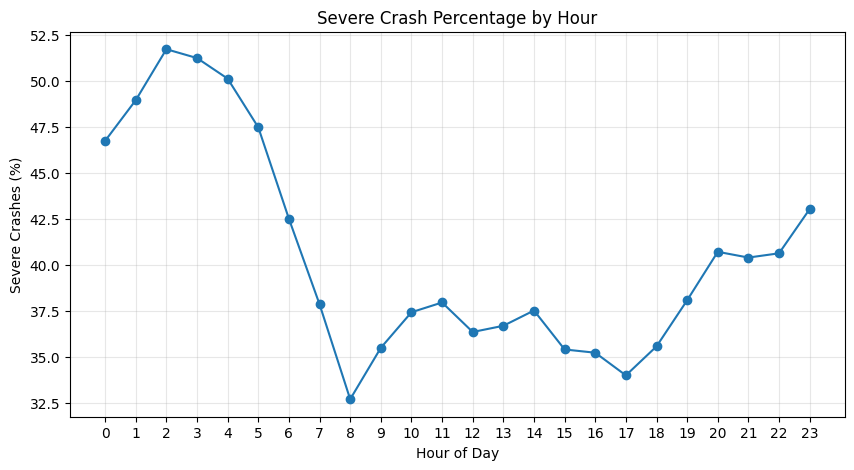

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(hour_severity.index, hour_severity["SEVERE_%"], marker="o")

plt.title("Severe Crash Percentage by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Severe Crashes (%)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()



#### Findings / Observations

- Crashes between midnight and early morning tend to result in more serious injuries or fatalities.
- At 2 AM, around 52% of recorded crashes were fatal or serious, compared with 33% at 8 AM.
- Daytime crashes generally have a lower percentage of severe outcomes than late-night crashes.



### 4.7 Lighting Conditions vs Crash Severity

Compare fatal and serious-injury crash percentages under different lighting conditions.

**Purpose:** Understand whether crashes in darkness tend to have more severe outcomes than crashes during daylight.

Lighting categories are based on the official Victorian Road Crash Data Dictionary.


In [ ]:

# Convert official lighting codes into readable labels
light_labels = {
    1: "Day",
    2: "Dusk / Dawn",
    3: "Dark - Lights ON",
    4: "Dark - Lights OFF",
    5: "Dark - No street lights",
    6: "Dark - Lights unknown",
    9: "Unknown"
}

master["LIGHT_CONDITION_DESC"] = master["LIGHT_CONDITION"].map(light_labels)

# Compare lighting conditions with crash severity
light_severity = pd.crosstab(
    master["LIGHT_CONDITION_DESC"],
    master["SEVERITY"],
    normalize="index"
) * 100

light_severity["SEVERE_%"] = light_severity[1] + light_severity[2]

display(light_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
LIGHT_CONDITION_DESC,,,
Dark - Lights OFF,2.95,39.23,42.18
Dark - Lights ON,1.71,39.66,41.38
Dark - Lights unknown,0.78,26.14,26.92
Dark - No street lights,5.36,46.07,51.43
Day,1.48,35.35,36.83
Dusk / Dawn,1.33,33.97,35.31
Unknown,0.48,15.39,15.87



#### Findings / Observations

- Crashes on dark roads without street lights tend to have more serious outcomes.
- Around 51% of crashes on unlit roads were fatal or serious, compared with 37% during daylight.
- Crashes on dark roads with street lights also had a higher percentage of severe outcomes (41%) than daytime crashes.



### 4.8 Weather Conditions vs Crash Severity

Examine how fatal and serious-injury crash percentages vary across different weather conditions.

**Purpose:** Understand whether adverse weather conditions are associated with more severe crash outcomes.


In [ ]:

# Explore weather condition categories
print(master["ATMOSPH_COND_DESC"].value_counts())


ATMOSPH_COND_DESC
Clear                           158505
Not known                        21065
Raining                          18221
Fog                               1259
Clear, Strong winds                533
                                 ...  
Clear, Raining                       1
Raining, Not known                   1
Strong winds, Raining, Smoke         1
Dust, Strong winds, Clear            1
Snowing, Fog, Raining                1
Name: count, Length: 61, dtype: int64


In [ ]:

# Group weather conditions
def weather_group(value):
    if value == "Not known":
        return "Unknown"
    elif value == "Clear":
        return "Clear"
    else:
        return "Adverse / Mixed weather"

master["WEATHER_GROUP"] = master["ATMOSPH_COND_DESC"].apply(weather_group)

# Compare weather groups with severity
weather_severity = pd.crosstab(
    master["WEATHER_GROUP"],
    master["SEVERITY"],
    normalize="index"
) * 100

weather_severity["SEVERE_%"] = weather_severity[1] + weather_severity[2]

display(weather_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
WEATHER_GROUP,,,
Adverse / Mixed weather,1.62,36.64,38.26
Clear,1.83,37.77,39.60
Unknown,0.57,20.10,20.68


#### Findings / Observations

- Around 40% of crashes in clear weather resulted in serious injuries or fatalities, compared with 38% in adverse or mixed weather.
- Weather conditions show only a small difference in severe-crash percentages.
- Based on this comparison, bad weather does not necessarily mean more severe crash outcomes.
- The adverse/mixed weather group combines several conditions, so individual effects of rain, fog or other weather conditions cannot be determined from this comparison.


### 4.9 Urban vs Rural Crash Severity

Compare fatal and serious-injury crash percentages across different urban and rural environments.

**Purpose:** Understand whether crashes in rural areas tend to have more severe outcomes than crashes in urban areas.


In [ ]:

# Explore urban and rural categories
print(master["DEG_URBAN_NAME"].value_counts())


DEG_URBAN_NAME
MELB_URBAN                 125358
RURAL_VICTORIA              43239
LARGE_PROVINCIAL_CITIES     11416
SMALL_CITIES                10177
TOWNS                        6030
Unknown                      2204
MELBOURNE_CBD                2009
SMALL_TOWNS                  1864
Name: count, dtype: int64


In [ ]:

# Compare crash severity across urban and rural areas
urban_severity = pd.crosstab(
    master["DEG_URBAN_NAME"],
    master["SEVERITY"],
    normalize="index"
) * 100

# Combine fatal and serious-injury percentages
urban_severity["SEVERE_%"] = urban_severity[1] + urban_severity[2]

# Display results
display(urban_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
DEG_URBAN_NAME,,,
LARGE_PROVINCIAL_CITIES,0.97,35.44,36.41
MELBOURNE_CBD,0.35,27.13,27.48
MELB_URBAN,0.97,34.00,34.96
RURAL_VICTORIA,4.14,43.81,47.95
SMALL_CITIES,1.21,29.10,30.30
SMALL_TOWNS,2.09,40.61,42.70
TOWNS,1.72,33.12,34.84
Unknown,0.05,25.45,25.50


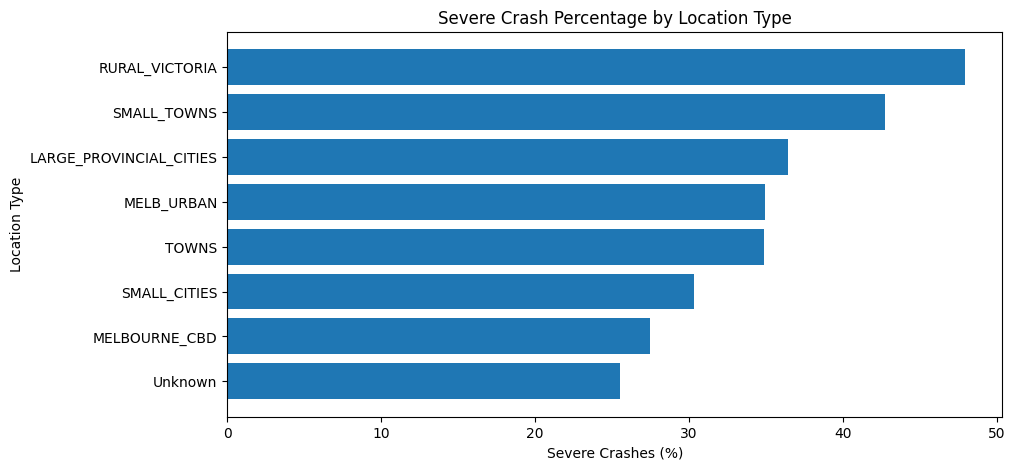

In [ ]:

# Sort locations by severe crash percentage
urban_plot = urban_severity["SEVERE_%"].sort_values()

# Create horizontal bar chart
plt.figure(figsize=(10, 5))
plt.barh(urban_plot.index, urban_plot.values)

plt.title("Severe Crash Percentage by Location Type")
plt.xlabel("Severe Crashes (%)")
plt.ylabel("Location Type")

plt.show()


#### Findings / Observations

- Crashes in rural Victoria tend to have more serious outcomes than crashes in Melbourne.
- Around 48% of rural crashes resulted in serious injuries or fatalities, compared with 35% in Melbourne's urban areas.
- Fatal crashes accounted for 4.14% of rural crashes, compared with just 0.35% in Melbourne CBD.
- Higher speed limits and different road conditions may partly explain the rural severity pattern. Further analysis is needed to investigate these relationships.


### 4.10 Number of Vehicles vs Crash Severity

Compare fatal and serious-injury crash percentages based on the number of vehicles involved.

**Purpose:** Understand whether single-vehicle and multi-vehicle crashes have different severity outcomes.


In [ ]:

# Group crashes by number of vehicles
master["VEHICLE_GROUP"] = master["NO_OF_VEHICLES"].apply(
    lambda x: "Single vehicle" if x == 1
    else "Multiple vehicles" if x >= 2
    else "Zero vehicles"
)

# Compare vehicle groups with crash severity
vehicle_severity = pd.crosstab(
    master["VEHICLE_GROUP"],
    master["SEVERITY"],
    normalize="index"
) * 100

vehicle_severity["SEVERE_%"] = vehicle_severity[1] + vehicle_severity[2]

display(vehicle_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
VEHICLE_GROUP,,,
Multiple vehicles,1.18,31.68,32.85
Single vehicle,2.72,44.43,47.15
Zero vehicles,0.00,57.14,57.14



#### Findings / Observations

- Single-vehicle crashes tend to have more serious outcomes than crashes involving multiple vehicles.
- Around 47% of single-vehicle crashes resulted in serious injuries or fatalities, compared with 33% of multi-vehicle crashes.
- The zero-vehicle category contains only 7 crashes, so its results are too limited for reliable conclusions.



### 4.11 Road Geometry vs Crash Severity

Examine how fatal and serious-injury crash percentages vary across different road layouts.

**Purpose:** Understand whether crashes at intersections, curves and other road layouts have different severity outcomes.


In [ ]:

# Explore road geometry categories
print(master["ROAD_GEOMETRY_DESC"].value_counts())


ROAD_GEOMETRY_DESC
Not at intersection      104255
Cross intersection        46389
T intersection            45471
Multiple intersection      3811
Unknown                    1503
Y intersection              673
Dead end                    178
Private property             11
Road closure                  6
Name: count, dtype: int64


In [ ]:

# Compare road geometry with crash severity
road_severity = pd.crosstab(
    master["ROAD_GEOMETRY_DESC"],
    master["SEVERITY"],
    normalize="index"
) * 100

# Combine fatal and serious-injury percentages
road_severity["SEVERE_%"] = road_severity[1] + road_severity[2]

# Display results
display(road_severity[[1, 2, "SEVERE_%"]].round(2))


SEVERITY,1,2,SEVERE_%
ROAD_GEOMETRY_DESC,,,
Cross intersection,0.98,32.01,32.99
Dead end,0.56,40.45,41.01
Multiple intersection,0.92,34.90,35.82
Not at intersection,2.27,38.20,40.47
Private property,0.00,27.27,27.27
Road closure,0.00,33.33,33.33
T intersection,1.14,35.01,36.15
Unknown,0.33,13.24,13.57
Y intersection,0.45,33.73,34.18



#### Findings / Observations

- Crashes occurring away from intersections tend to have more serious outcomes.
- Around 40% of crashes away from intersections resulted in serious injuries or fatalities, compared with 33% at cross intersections.
- Fatal crashes accounted for 2.27% of crashes away from intersections, compared with 0.98% at cross intersections.



### 4.12 Final EDA Summary

#### Key Findings

Analysis of 202,297 Victorian road crashes identified several important patterns:

- **Speed limits:** Crashes on higher-speed roads tend to have more serious outcomes.
- **Time:** Crashes between midnight and early morning show higher percentages of serious injuries and fatalities.
- **Lighting:** Crashes on dark roads without street lights have more severe outcomes than daytime crashes.
- **Location:** Rural crashes tend to be more severe than crashes in Melbourne's urban areas.
- **Vehicle involvement:** Single-vehicle crashes have a higher percentage of severe outcomes than multi-vehicle crashes.
- **Road layout:** Crashes away from intersections tend to have more serious outcomes.
- **Weather:** Severe-crash percentages are relatively similar in clear and adverse weather.

#### Data Limitations

- The dataset covers January 2012 to February 2026, so 2026 is incomplete and should not be compared directly with full years.
- Only 4 non-injury crashes are recorded, meaning the dataset cannot reliably represent all road crashes in Victoria.
- Some records have missing location, vehicle-age or other information.
- The findings describe severity among recorded crashes, not the likelihood of a crash occurring.
- Relationships identified during EDA do not necessarily indicate causation.

#### Conclusion

Higher speed limits, overnight hours, unlit roads, rural locations and single-vehicle crashes are associated with a greater proportion of severe crash outcomes.

These findings provide a foundation for further investigation using SQL and Power BI, followed by machine learning to predict crash severity.


### 4.13 Export Final Dataset

Save the updated master dataset after completing exploratory data analysis.

**Purpose:** Preserve the cleaned and derived columns for SQL analysis, Power BI visualisation and machine learning preparation.

In [ ]:
# Save the final dataset to Google Drive
final_path = "/content/drive/MyDrive/Victoria RoadSafe - Crash Intelligence and Severity Prediction/master_crash_data.csv"

master.to_csv(final_path, index=False)

print("Final dataset saved successfully!")
print("Rows:", len(master))
print("Columns:", master.shape[1])

Final dataset saved successfully!
Rows: 202297
Columns: 34
